---
title: "MUSAE GitHub Network Analysis (Chapters 2-7 Lens)"
author: "Codex"
date: "2026-03-08"
format:
  html:
    toc: true
    code-fold: false
execute:
  echo: true
  warning: false
  message: false
jupyter: python3
---

## Scope

This report follows the Chapter 2-7 flow from *Statistical Analysis of Network Data with R*:

- Chapter 2: Manipulate graph data and decorate vertices with attributes.
- Chapter 3: Visualize the graph with practical layouts for large networks.
- Chapter 4: Describe graph characteristics (degree, centrality, cohesion, assortativity).
- Chapter 5: Compare observed structure to mathematical random-graph baselines.
- Chapter 6: Fit statistical network-style models (dyad logistic proxy, block model, latent embedding).
- Chapter 7: Perform topology inference through link prediction.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.linalg import svds
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
rng = np.random.default_rng(SEED)

ROOT = Path(".").resolve()
OUT_DIR = ROOT / "codex_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Avoid matplotlib cache warnings in restricted environments.
os.environ.setdefault("MPLCONFIGDIR", str((ROOT / ".mplconfig").resolve()))

'/Users/farhan/Documents/GitHub/github_analysis/.mplconfig'

In [2]:
def approximate_average_path_length(graph: nx.Graph, sample_size: int = 256, seed: int = SEED) -> float:
    """Approximate average shortest path length using sampled sources."""
    local_rng = np.random.default_rng(seed)
    nodes = np.array(list(graph.nodes()))
    if len(nodes) == 0:
        return float("nan")
    k = min(sample_size, len(nodes))
    starts = local_rng.choice(nodes, size=k, replace=False)
    dists = []
    for s in starts:
        lengths = nx.single_source_shortest_path_length(graph, int(s))
        dists.extend(lengths.values())
    return float(np.mean(dists))

In [3]:
def sample_non_edges(
    n_nodes: int,
    existing_edges: set[tuple[int, int]],
    n_samples: int,
    local_rng: np.random.Generator,
    forbidden: set[tuple[int, int]] | None = None,
) -> list[tuple[int, int]]:
    """Sample non-edges uniformly by rejection sampling."""
    forbidden = forbidden or set()
    samples = []
    seen = set()
    while len(samples) < n_samples:
        u = int(local_rng.integers(0, n_nodes))
        v = int(local_rng.integers(0, n_nodes))
        if u == v:
            continue
        e = (u, v) if u < v else (v, u)
        if e in existing_edges or e in forbidden or e in seen:
            continue
        seen.add(e)
        samples.append((u, v))
    return samples

In [4]:
def compute_link_features(
    pairs: list[tuple[int, int]],
    neighbor_sets: dict[int, set[int]],
    degree_map: dict[int, int],
    ml_target_arr: np.ndarray,
) -> pd.DataFrame:
    """Compute common link-prediction heuristics for node pairs."""
    cn = np.zeros(len(pairs), dtype=float)
    jc = np.zeros(len(pairs), dtype=float)
    aa = np.zeros(len(pairs), dtype=float)
    pa = np.zeros(len(pairs), dtype=float)
    same_type = np.zeros(len(pairs), dtype=float)

    for i, (u, v) in enumerate(pairs):
        nu = neighbor_sets[u]
        nv = neighbor_sets[v]
        inter = nu & nv
        union_size = len(nu | nv)

        cn[i] = len(inter)
        jc[i] = len(inter) / union_size if union_size else 0.0

        aa_score = 0.0
        for w in inter:
            dw = degree_map[w]
            if dw > 1:
                aa_score += 1.0 / np.log(dw)
        aa[i] = aa_score

        pa[i] = degree_map[u] * degree_map[v]
        same_type[i] = 1.0 if ml_target_arr[u] == ml_target_arr[v] else 0.0

    return pd.DataFrame(
        {
            "common_neighbors": cn,
            "jaccard": jc,
            "adamic_adar": aa,
            "preferential_attachment": pa,
            "same_ml_target": same_type,
        }
    )

In [5]:
def row_from_graph(model_name: str, rep: int, graph: nx.Graph) -> dict:
    """Summary row for model-comparison tables."""
    if nx.is_connected(graph):
        giant = graph
    else:
        giant_nodes = max(nx.connected_components(graph), key=len)
        giant = graph.subgraph(giant_nodes).copy()

    return {
        "model": model_name,
        "replicate": rep,
        "nodes": graph.number_of_nodes(),
        "edges": graph.number_of_edges(),
        "transitivity": nx.transitivity(graph),
        "approx_avg_path_length": approximate_average_path_length(giant, sample_size=128, seed=SEED + rep),
    }

In [6]:
def boxplot_with_compat_labels(ax, groups, labels):
    """Matplotlib version compatibility for boxplot tick labels."""
    try:
        return ax.boxplot(groups, tick_labels=labels)
    except TypeError:
        return ax.boxplot(groups, labels=labels)

## Data Loading

In [7]:
edges_df = pd.read_csv(ROOT / "musae_git_edges.csv")
target_df = pd.read_csv(ROOT / "musae_git_target.csv")

In [8]:
n_nodes = int(target_df["id"].max()) + 1

G = nx.Graph()
G.add_nodes_from(range(n_nodes))
G.add_edges_from(edges_df[["id_1", "id_2"]].itertuples(index=False, name=None))
G.remove_edges_from(nx.selfloop_edges(G))

In [9]:
name_map = dict(zip(target_df["id"], target_df["name"]))
ml_target_arr = np.zeros(n_nodes, dtype=int)
for i, t in target_df[["id", "ml_target"]].itertuples(index=False, name=None):
    ml_target_arr[int(i)] = int(t)

nx.set_node_attributes(G, {int(i): str(n) for i, n in target_df[["id", "name"]].itertuples(index=False, name=None)}, "name")
nx.set_node_attributes(G, {int(i): int(t) for i, t in target_df[["id", "ml_target"]].itertuples(index=False, name=None)}, "ml_target")

edge_set = {(u, v) if u < v else (v, u) for u, v in G.edges()}

In [10]:
overview = pd.DataFrame(
    [
        {
            "nodes": G.number_of_nodes(),
            "edges": G.number_of_edges(),
            "density": nx.density(G),
            "is_connected": nx.is_connected(G),
        }
    ]
)

print("Graph overview")
print(overview.to_string(index=False))

Graph overview
 nodes  edges  density  is_connected
 37700 289003 0.000407          True


## Chapter 2: Manipulating Network Data

In [11]:
ml_counts = target_df["ml_target"].value_counts().sort_index().rename_axis("ml_target").reset_index(name="count")
ml_counts["fraction"] = ml_counts["count"] / ml_counts["count"].sum()

degree_map_full = dict(G.degree())
top_hubs = (
    pd.DataFrame({"id": list(degree_map_full.keys()), "degree": list(degree_map_full.values())})
    .sort_values("degree", ascending=False)
    .head(15)
)
top_hubs["name"] = top_hubs["id"].map(name_map)
top_hubs["ml_target"] = top_hubs["id"].map(lambda x: int(ml_target_arr[x]))

data_quality = pd.DataFrame(
    [
        {
            "self_loops": nx.number_of_selfloops(G),
            "isolated_nodes": sum(1 for _, d in G.degree() if d == 0),
            "node_attributes": "name, ml_target",
        }
    ]
)

In [12]:
print("Data quality checks")
print(data_quality.to_string(index=False))
print("\nml_target balance")
print(ml_counts.to_string(index=False))
print("\nTop hubs")
print(top_hubs[["id", "name", "degree", "ml_target"]].to_string(index=False))

Data quality checks
 self_loops  isolated_nodes node_attributes
          0               0 name, ml_target

ml_target balance
 ml_target  count  fraction
         0  27961  0.741671
         1   9739  0.258329

Top hubs
   id              name  degree  ml_target
31890      dalinhuang99    9458          0
27803            nfultz    7085          0
35773        addyosmani    3324          0
19222           Bunlong    2958          0
13638 gabrielpconceicao    2468          0
36652           rfthusn    2343          0
18163          nelsonic    1924          0
 9051            getify    1797          0
35008               mdo    1571          0
10001       ronenhamias    1568          0
36628    SuriyaaKudoIsc    1507          0
 7027           jeresig    1485          0
19253       JonnyBanana    1404          0
 2078          mbostock    1368          0
33671     shayan-taheri    1347          0


In [13]:
ml_counts.to_csv(OUT_DIR / "chapter2_ml_target_balance.csv", index=False)
top_hubs.to_csv(OUT_DIR / "chapter2_top_hubs.csv", index=False)

## Chapter 3: Visualizing Network Data

In [14]:
# Large-network visualization is done on a high-core subgraph for readability.
core_map = nx.core_number(G)
core_threshold = 100
core_nodes = [n for n, c in core_map.items() if c >= core_threshold]

if len(core_nodes) >= 1200:
    vis_nodes = rng.choice(np.array(core_nodes), size=1200, replace=False)
elif len(core_nodes) >= 300:
    vis_nodes = np.array(core_nodes)
else:
    top_by_degree = np.array(sorted(degree_map_full, key=degree_map_full.get, reverse=True)[:1200])
    vis_nodes = top_by_degree

G_vis = G.subgraph(vis_nodes).copy()
pos = nx.spring_layout(G_vis, seed=SEED, k=0.15, iterations=120)

node_colors = ["#1f77b4" if ml_target_arr[n] == 0 else "#d62728" for n in G_vis.nodes()]
node_sizes = [10 + 2.2 * np.sqrt(degree_map_full[n]) for n in G_vis.nodes()]

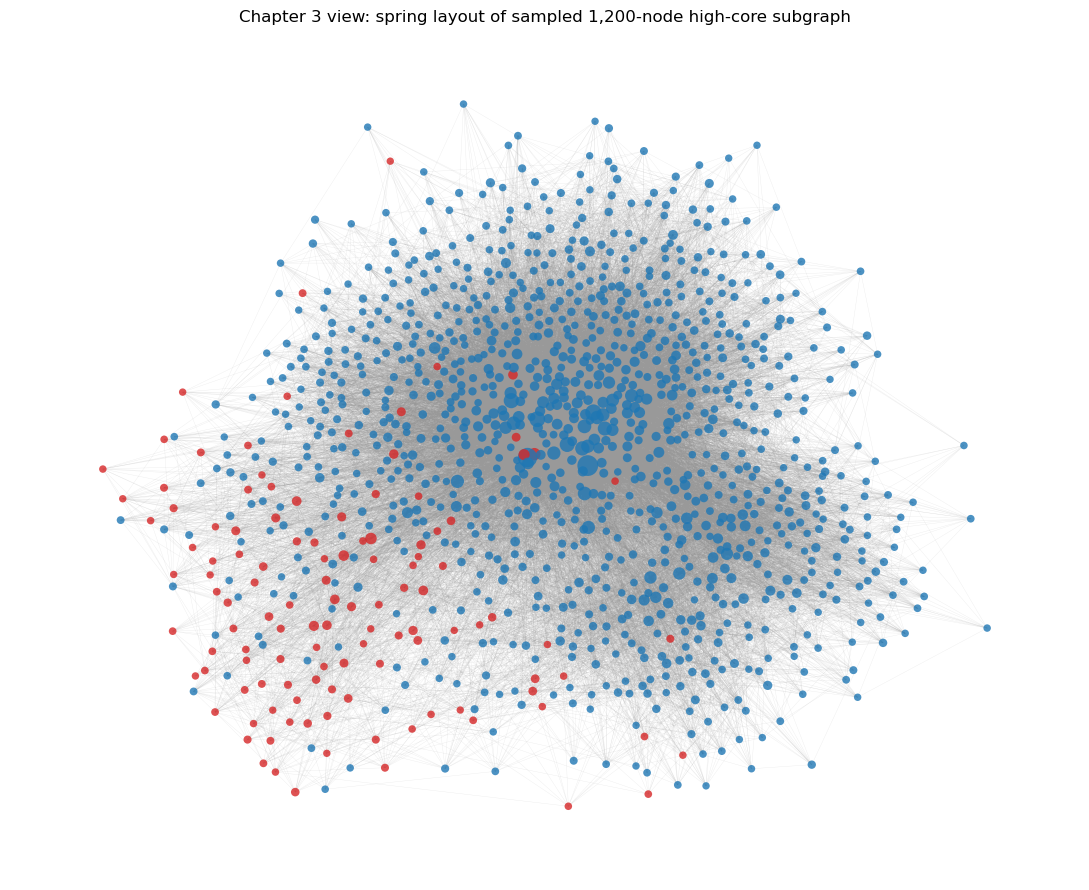

In [15]:
plt.figure(figsize=(11, 9))
nx.draw_networkx_edges(G_vis, pos, width=0.25, alpha=0.20, edge_color="#999999")
nx.draw_networkx_nodes(G_vis, pos, node_size=node_sizes, node_color=node_colors, alpha=0.80, linewidths=0)
plt.title(f"Chapter 3 view: spring layout of sampled {G_vis.number_of_nodes():,}-node high-core subgraph")
plt.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "chapter3_layout_high_core.png", dpi=240)
plt.show()

## Chapter 4: Descriptive Analysis of Graph Characteristics

In [16]:
degree_vals = np.fromiter((d for _, d in G.degree()), dtype=float)

degree_stats = pd.DataFrame(
    [
        {
            "mean_degree": degree_vals.mean(),
            "std_degree": degree_vals.std(),
            "median_degree": float(np.median(degree_vals)),
            "max_degree": degree_vals.max(),
            "p90_degree": float(np.percentile(degree_vals, 90)),
            "p99_degree": float(np.percentile(degree_vals, 99)),
        }
    ]
)

sorted_degrees = np.sort(degree_vals)
ccdf = 1.0 - (np.arange(1, len(sorted_degrees) + 1) / len(sorted_degrees))

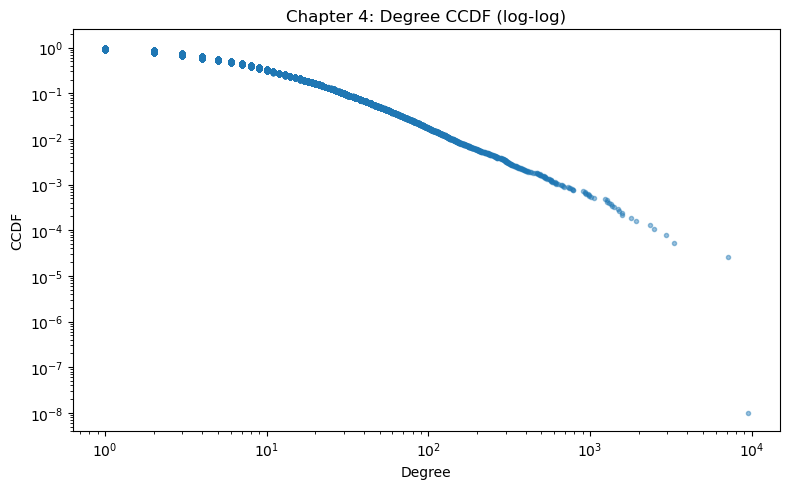

In [17]:
plt.figure(figsize=(8, 5))
plt.loglog(sorted_degrees, np.maximum(ccdf, 1e-8), marker=".", linestyle="none", alpha=0.45)
plt.xlabel("Degree")
plt.ylabel("CCDF")
plt.title("Chapter 4: Degree CCDF (log-log)")
plt.tight_layout()
plt.savefig(OUT_DIR / "chapter4_degree_ccdf.png", dpi=240)
plt.show()

In [18]:
pagerank = nx.pagerank(G, alpha=0.85, tol=1e-6)
centrality_df = pd.DataFrame(
    {
        "id": list(G.nodes()),
        "name": [name_map.get(i, str(i)) for i in G.nodes()],
        "ml_target": [int(ml_target_arr[i]) for i in G.nodes()],
        "degree": [degree_map_full[i] for i in G.nodes()],
        "degree_centrality": [degree_map_full[i] / (n_nodes - 1) for i in G.nodes()],
        "pagerank": [pagerank[i] for i in G.nodes()],
        "core_number": [core_map[i] for i in G.nodes()],
    }
)

top_central = centrality_df.sort_values("pagerank", ascending=False).head(20).copy()

global_metrics = pd.DataFrame(
    [
        {
            "components": nx.number_connected_components(G),
            "transitivity": nx.transitivity(G),
            "degree_assortativity": nx.degree_assortativity_coefficient(G),
            "ml_target_assortativity": nx.attribute_assortativity_coefficient(G, "ml_target"),
            "approx_avg_path_length": approximate_average_path_length(G, sample_size=256, seed=SEED),
            "max_core": max(core_map.values()),
        }
    ]
)

print("Degree summary")
print(degree_stats.to_string(index=False))
print("\nGlobal structural metrics")
print(global_metrics.to_string(index=False))
print("\nTop 20 by PageRank")
print(top_central[["id", "name", "degree", "pagerank", "core_number", "ml_target"]].to_string(index=False))

Degree summary
 mean_degree  std_degree  median_degree  max_degree  p90_degree  p99_degree
   15.331724   80.787031            6.0      9458.0        30.0      138.01

Global structural metrics
 components  transitivity  degree_assortativity  ml_target_assortativity  approx_avg_path_length  max_core
          1      0.012357             -0.075217                 0.377822                 3.18729        34

Top 20 by PageRank
   id              name  degree  pagerank  core_number  ml_target
31890      dalinhuang99    9458  0.016514           34          0
27803            nfultz    7085  0.011451           34          0
35773        addyosmani    3324  0.004919           34          0
19222           Bunlong    2958  0.004669           34          0
13638 gabrielpconceicao    2468  0.003875           34          0
36652           rfthusn    2343  0.003799           34          0
18163          nelsonic    1924  0.003381           34          0
 9051            getify    1797  0.002722   

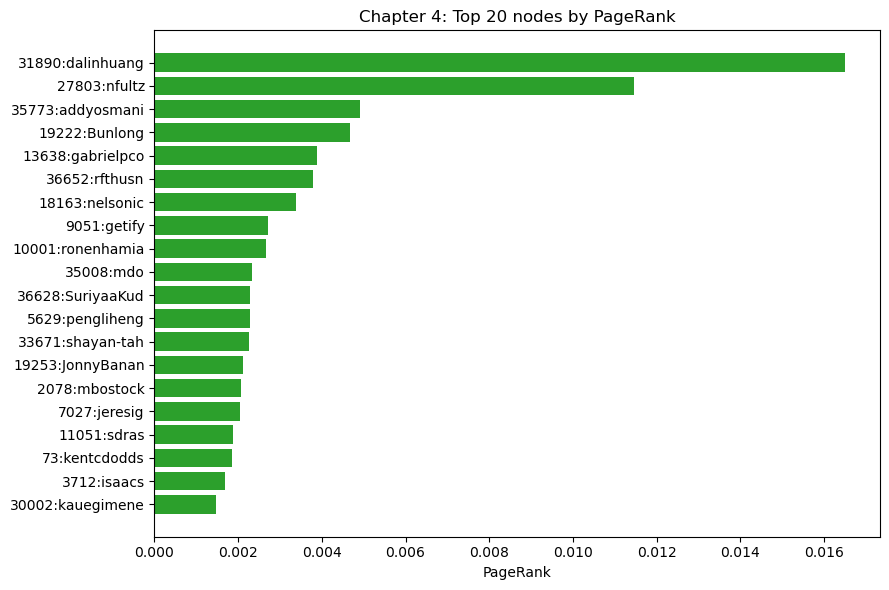

In [19]:
top_plot = top_central.sort_values("pagerank", ascending=True)
labels = [f"{i}:{n[:10]}" for i, n in zip(top_plot["id"], top_plot["name"])]
plt.figure(figsize=(9, 6))
plt.barh(labels, top_plot["pagerank"], color="#2ca02c")
plt.xlabel("PageRank")
plt.title("Chapter 4: Top 20 nodes by PageRank")
plt.tight_layout()
plt.savefig(OUT_DIR / "chapter4_top_pagerank.png", dpi=240)
plt.show()

In [20]:
degree_stats.to_csv(OUT_DIR / "chapter4_degree_stats.csv", index=False)
global_metrics.to_csv(OUT_DIR / "chapter4_global_metrics.csv", index=False)
top_central.to_csv(OUT_DIR / "chapter4_top_centrality.csv", index=False)

## Chapter 5: Mathematical Models for Network Graphs

In [21]:
n = G.number_of_nodes()
m = G.number_of_edges()
p_er = (2.0 * m) / (n * (n - 1))
degree_sequence = [degree_map_full[i] for i in range(n)]

model_rows = [row_from_graph("Observed", 0, G)]

num_reps = 2
for rep in range(1, num_reps + 1):
    er_graph = nx.gnp_random_graph(n, p_er, seed=SEED + rep)
    model_rows.append(row_from_graph("Erdos-Renyi", rep, er_graph))

    cfg_graph = nx.configuration_model(degree_sequence, seed=SEED + 100 + rep)
    cfg_graph = nx.Graph(cfg_graph)
    cfg_graph.remove_edges_from(nx.selfloop_edges(cfg_graph))
    cfg_graph.add_nodes_from(range(n))
    model_rows.append(row_from_graph("Configuration", rep, cfg_graph))

model_cmp = pd.DataFrame(model_rows)

obs = model_cmp[model_cmp["model"] == "Observed"].iloc[0]
er_mean = model_cmp[model_cmp["model"] == "Erdos-Renyi"][["transitivity", "approx_avg_path_length"]].mean()
small_world_score = (obs["transitivity"] / er_mean["transitivity"]) / (
    obs["approx_avg_path_length"] / er_mean["approx_avg_path_length"]
)

# Rough tail exponent diagnostic for preferential attachment behavior.
deg_tail_cut = np.percentile(degree_vals, 90)
tail = degree_vals[degree_vals >= deg_tail_cut]
uniq, counts = np.unique(tail, return_counts=True)
if len(uniq) >= 2:
    slope, intercept = np.polyfit(np.log(uniq), np.log(counts), 1)
    tail_gamma = -float(slope)
else:
    tail_gamma = float("nan")

chapter5_summary = pd.DataFrame(
    [
        {
            "p_er": p_er,
            "small_world_score_vs_er": small_world_score,
            "tail_exponent_gamma_estimate": tail_gamma,
        }
    ]
)

In [22]:
print("Model comparison (first rows)")
print(model_cmp.head(10).to_string(index=False))
print("\nChapter 5 summary")
print(chapter5_summary.to_string(index=False))

Model comparison (first rows)
        model  replicate  nodes  edges  transitivity  approx_avg_path_length
     Observed          0  37700 289003      0.012357                3.316813
  Erdos-Renyi          1  37700 288177      0.000397                4.162438
Configuration          1  37700 277119      0.017082                3.293159
  Erdos-Renyi          2  37700 289869      0.000413                4.151171
Configuration          2  37700 277153      0.017126                3.331695

Chapter 5 summary
    p_er  small_world_score_vs_er  tail_exponent_gamma_estimate
0.000407                38.238766                      1.218613


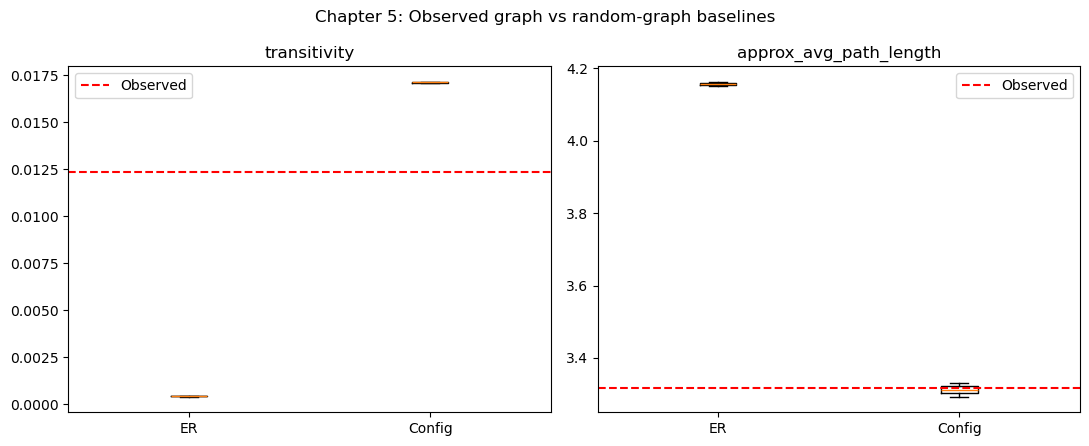

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
plot_df = model_cmp[model_cmp["model"] != "Observed"].copy()
for idx, metric in enumerate(["transitivity", "approx_avg_path_length"]):
    groups = [plot_df[plot_df["model"] == "Erdos-Renyi"][metric].values,
              plot_df[plot_df["model"] == "Configuration"][metric].values]
    boxplot_with_compat_labels(ax[idx], groups, labels=["ER", "Config"])
    ax[idx].axhline(obs[metric], color="red", linestyle="--", linewidth=1.5, label="Observed")
    ax[idx].set_title(metric)
    ax[idx].legend(loc="best")
plt.suptitle("Chapter 5: Observed graph vs random-graph baselines")
plt.tight_layout()
plt.savefig(OUT_DIR / "chapter5_model_comparison.png", dpi=240)
plt.show()

In [24]:
model_cmp.to_csv(OUT_DIR / "chapter5_model_comparison.csv", index=False)
chapter5_summary.to_csv(OUT_DIR / "chapter5_summary.csv", index=False)

## Chapter 6: Statistical Models for Network Graphs

In [25]:
# 6.1 Dyad-level logistic proxy (ERGMs are conceptually similar but not fit directly here).
pos_edges = list(G.edges())
rng.shuffle(pos_edges)

n_pos = min(60_000, len(pos_edges))
train_pos = pos_edges[:n_pos]
train_neg = sample_non_edges(n, edge_set, n_pos, rng)

pairs = train_pos + train_neg
y_dyad = np.concatenate([np.ones(n_pos), np.zeros(n_pos)])

neighbors_full = {u: set(G.neighbors(u)) for u in G.nodes()}
X_dyad = compute_link_features(pairs, neighbors_full, degree_map_full, ml_target_arr)
X_dyad["log_degree_product"] = np.log1p(X_dyad["preferential_attachment"])
X_dyad = X_dyad[["common_neighbors", "jaccard", "adamic_adar", "same_ml_target", "log_degree_product"]]

X_train, X_test, y_train, y_test = train_test_split(
    X_dyad, y_dyad, test_size=0.25, random_state=SEED, stratify=y_dyad
)

dyad_model = Pipeline(
    [
        ("scale", StandardScaler()),
        ("lr", LogisticRegression(max_iter=1200, random_state=SEED, solver="liblinear")),
    ]
)
dyad_model.fit(X_train, y_train)
dyad_auc = roc_auc_score(y_test, dyad_model.predict_proba(X_test)[:, 1])

coef = dyad_model.named_steps["lr"].coef_.ravel()
coef_df = pd.DataFrame({"feature": X_train.columns, "coefficient": coef}).sort_values("coefficient", ascending=False)

In [26]:
# 6.2 Block model (two-group SBM using known ml_target groups).
n0 = int((ml_target_arr == 0).sum())
n1 = int((ml_target_arr == 1).sum())

count_00 = 0
count_11 = 0
count_01 = 0
for u, v in G.edges():
    a = ml_target_arr[u]
    b = ml_target_arr[v]
    if a == 0 and b == 0:
        count_00 += 1
    elif a == 1 and b == 1:
        count_11 += 1
    else:
        count_01 += 1

possible_00 = n0 * (n0 - 1) / 2
possible_11 = n1 * (n1 - 1) / 2
possible_01 = n0 * n1

block_probs = pd.DataFrame(
    [
        {"block": "0-0", "observed_edges": count_00, "possible_pairs": possible_00, "edge_probability": count_00 / possible_00},
        {"block": "0-1", "observed_edges": count_01, "possible_pairs": possible_01, "edge_probability": count_01 / possible_01},
        {"block": "1-1", "observed_edges": count_11, "possible_pairs": possible_11, "edge_probability": count_11 / possible_11},
    ]
)

In [27]:
# 6.3 Latent model proxy: spectral embedding of adjacency.
rows = edges_df["id_1"].to_numpy()
cols = edges_df["id_2"].to_numpy()
data = np.ones(len(edges_df), dtype=np.float32)
A = sparse.coo_matrix((data, (rows, cols)), shape=(n, n))
A = (A + A.T).tocsr()

u, s, vt = svds(A.asfptype(), k=2, which="LM")
order = np.argsort(-s)
u = u[:, order]
s = s[order]
latent_xy = u * s

X_lat_train, X_lat_test, y_lat_train, y_lat_test = train_test_split(
    latent_xy, ml_target_arr, test_size=0.25, random_state=SEED, stratify=ml_target_arr
)
latent_clf = LogisticRegression(max_iter=1000, random_state=SEED, solver="liblinear")
latent_clf.fit(X_lat_train, y_lat_train)
latent_auc = roc_auc_score(y_lat_test, latent_clf.predict_proba(X_lat_test)[:, 1])

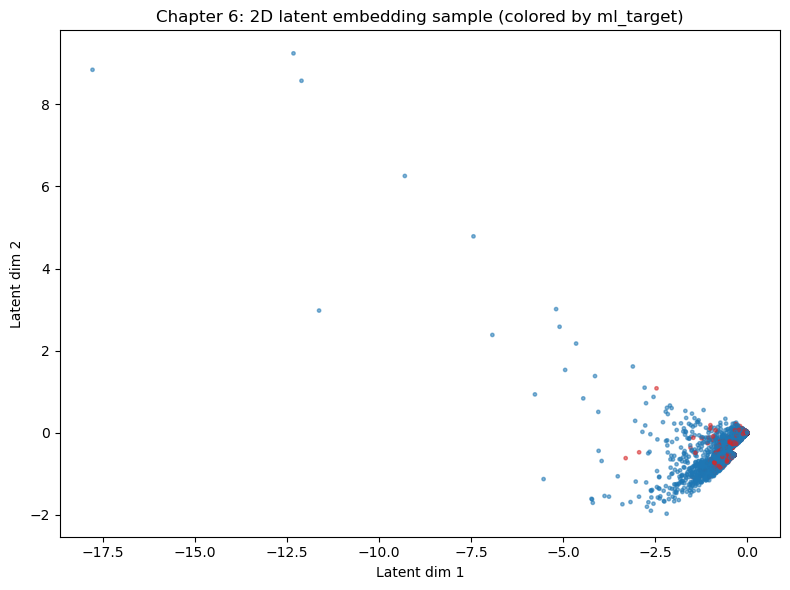

In [28]:
sample_n = min(6000, n)
sample_idx = rng.choice(np.arange(n), size=sample_n, replace=False)
plt.figure(figsize=(8, 6))
plt.scatter(
    latent_xy[sample_idx, 0],
    latent_xy[sample_idx, 1],
    c=np.where(ml_target_arr[sample_idx] == 0, "#1f77b4", "#d62728"),
    s=6,
    alpha=0.55,
)
plt.title("Chapter 6: 2D latent embedding sample (colored by ml_target)")
plt.xlabel("Latent dim 1")
plt.ylabel("Latent dim 2")
plt.tight_layout()
plt.savefig(OUT_DIR / "chapter6_latent_embedding.png", dpi=240)
plt.show()

In [29]:
chapter6_summary = pd.DataFrame(
    [
        {
            "dyad_logistic_auc": dyad_auc,
            "latent_embedding_target_auc": latent_auc,
            "ml_target_assortativity": nx.attribute_assortativity_coefficient(G, "ml_target"),
        }
    ]
)

print("Dyad-logistic coefficients")
print(coef_df.to_string(index=False))
print("\nBlock-model edge probabilities")
print(block_probs.to_string(index=False))
print("\nChapter 6 summary")
print(chapter6_summary.to_string(index=False))

Dyad-logistic coefficients
           feature  coefficient
       adamic_adar    25.566720
log_degree_product     2.566680
    same_ml_target     0.261843
           jaccard     0.183303
  common_neighbors    -9.549192

Block-model edge probabilities
block  observed_edges  possible_pairs  edge_probability
  0-0          224623     390894780.0          0.000575
  0-1           44696     272312179.0          0.000164
  1-1           19684      47419191.0          0.000415

Chapter 6 summary
 dyad_logistic_auc  latent_embedding_target_auc  ml_target_assortativity
          0.951075                     0.686119                 0.377822


In [30]:
coef_df.to_csv(OUT_DIR / "chapter6_dyad_logistic_coefficients.csv", index=False)
block_probs.to_csv(OUT_DIR / "chapter6_block_model_probabilities.csv", index=False)
chapter6_summary.to_csv(OUT_DIR / "chapter6_summary.csv", index=False)

## Chapter 7: Network Topology Inference (Link Prediction)

In [31]:
all_edges = list(G.edges())
rng.shuffle(all_edges)

n_test = int(0.2 * len(all_edges))
test_pos = all_edges[:n_test]
train_edges = all_edges[n_test:]

G_train = G.copy()
G_train.remove_edges_from(test_pos)

test_neg = sample_non_edges(n, edge_set, n_test, rng)

# Use a manageable training subset for stacked classifier.
n_train_lp = min(60_000, len(train_edges))
train_pos_lp = train_edges[:n_train_lp]
train_neg_lp = sample_non_edges(n, edge_set, n_train_lp, rng, forbidden={(u, v) if u < v else (v, u) for u, v in test_neg})

neighbors_train = {u: set(G_train.neighbors(u)) for u in G_train.nodes()}
degree_train = dict(G_train.degree())

X_train_lp = compute_link_features(train_pos_lp + train_neg_lp, neighbors_train, degree_train, ml_target_arr)
y_train_lp = np.concatenate([np.ones(len(train_pos_lp)), np.zeros(len(train_neg_lp))])

X_test_lp = compute_link_features(test_pos + test_neg, neighbors_train, degree_train, ml_target_arr)
y_test_lp = np.concatenate([np.ones(len(test_pos)), np.zeros(len(test_neg))])

In [32]:
lp_auc_rows = []
for col in ["common_neighbors", "jaccard", "adamic_adar", "preferential_attachment", "same_ml_target"]:
    lp_auc_rows.append({"model": col, "auc": roc_auc_score(y_test_lp, X_test_lp[col])})

stack_lp = Pipeline(
    [
        ("scale", StandardScaler()),
        ("lr", LogisticRegression(max_iter=1200, random_state=SEED, solver="liblinear")),
    ]
)
stack_lp.fit(X_train_lp, y_train_lp)
stack_scores = stack_lp.predict_proba(X_test_lp)[:, 1]
stack_auc = roc_auc_score(y_test_lp, stack_scores)
lp_auc_rows.append({"model": "stacked_logistic", "auc": stack_auc})

lp_auc_df = pd.DataFrame(lp_auc_rows).sort_values("auc", ascending=False)

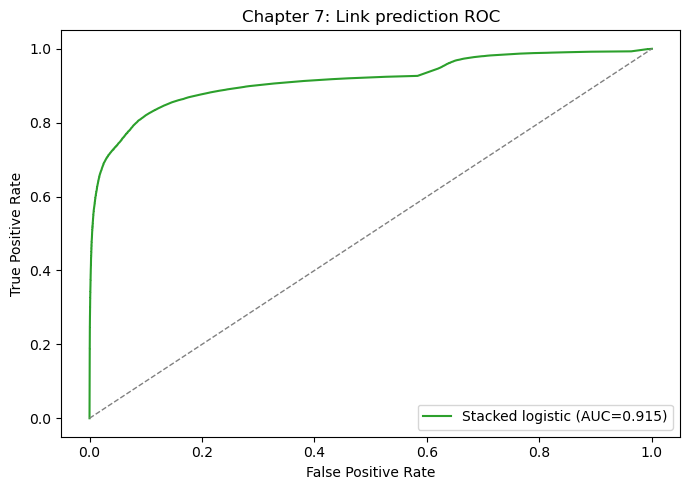

In [33]:
fpr, tpr, _ = roc_curve(y_test_lp, stack_scores)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Stacked logistic (AUC={stack_auc:.3f})", color="#2ca02c")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Chapter 7: Link prediction ROC")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUT_DIR / "chapter7_link_prediction_roc.png", dpi=240)
plt.show()

In [34]:
print("Link prediction AUC ranking")
print(lp_auc_df.to_string(index=False))

lp_auc_df.to_csv(OUT_DIR / "chapter7_link_prediction_auc.csv", index=False)

Link prediction AUC ranking
                  model      auc
       stacked_logistic 0.914816
preferential_attachment 0.908650
            adamic_adar 0.826029
       common_neighbors 0.820392
                jaccard 0.785673
         same_ml_target 0.614135


## Artifacts

In [35]:
artifacts = sorted([p.name for p in OUT_DIR.glob("*")])
print("Saved files in codex_outputs/")
for f in artifacts:
    print("-", f)

Saved files in codex_outputs/
- chapter2_ml_target_balance.csv
- chapter2_top_hubs.csv
- chapter3_layout_high_core.pdf
- chapter3_layout_high_core.png
- chapter4_community_sizes.csv
- chapter4_community_sizes.pdf
- chapter4_community_summary.csv
- chapter4_core_distribution.pdf
- chapter4_degree_ccdf.pdf
- chapter4_degree_ccdf.png
- chapter4_degree_hist_linear.pdf
- chapter4_degree_hist_log.pdf
- chapter4_degree_stats.csv
- chapter4_global_metrics.csv
- chapter4_hclust_cluster_sizes.csv
- chapter4_hclust_cluster_sizes.pdf
- chapter4_hclust_dendrogram.pdf
- chapter4_laplacian_largest.csv
- chapter4_laplacian_smallest.csv
- chapter4_laplacian_smallest_plot.pdf
- chapter4_laplacian_subgraph_spectrum.csv
- chapter4_laplacian_subgraph_spectrum.pdf
- chapter4_laplacian_summary.csv
- chapter4_local_clustering.pdf
- chapter4_mixing_heatmap.pdf
- chapter4_mixing_matrix.csv
- chapter4_path_length_sample.pdf
- chapter4_rank_degree.pdf
- chapter4_top_centrality.csv
- chapter4_top_pagerank.pdf
- ch